# CommercePulse Europe — Decision Analysis

## tl;dr

This reproducible notebook analyzes a **deterministic synthetic European commerce scenario**. ECB FX observations are real reference data; no result describes a real company.

- Comparison: **2025Q1 versus 2025Q2**.
- Current-quarter net revenue: **EUR 582,689** (+12.8% versus the prior quarter).
- Current-quarter contribution margin: **EUR 39,715**; margin rate moved **-11.0 pp**.
- Largest negative contribution driver: **Channel: Paid Search** (EUR -23,145).
- Recommendation: protect profitable growth by addressing discount depth, North-hub delivery reliability, mobile latency, and replenishment exceptions with explicit guardrails.


## Context & Methods

**Decision.** Where should commercial, product, operations, finance, and inventory leaders intervene to improve growth quality rather than revenue alone?

**Unit of analysis.** Atomic order items for profitability; sessions for conversion; order-item returns for refund economics; order fulfillment for SLA; product-market-month snapshots for inventory.

### Key Assumptions

- Last-touch channel attribution is descriptive, not causal incrementality.
- Contribution margin equals net revenue after discounts and refunds, less COGS, marketing, outbound fulfillment, and return handling, plus recoverable COGS.
- Rates use summed numerators and denominators; group rates are never averaged without weights.
- Logistic regression estimates associations and cannot establish causal lift.
- The forecast is a planning benchmark with out-of-sample backtesting, not a promise.


In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'artifacts' / 'analysis').exists():
    ROOT = ROOT.parent
ANALYSIS = ROOT / 'artifacts' / 'analysis'
VALIDATION = ROOT / 'artifacts' / 'validation'

monthly = pd.read_csv(ANALYSIS / 'monthly_kpis.csv', parse_dates=['month_start'])
overall = pd.read_csv(ANALYSIS / 'overall_kpis.csv')
funnel = pd.read_csv(ANALYSIS / 'funnel.csv')
cohort = pd.read_csv(ANALYSIS / 'cohort_retention.csv')
roots = pd.read_csv(ANALYSIS / 'root_causes.csv')
forecast = pd.read_csv(ANALYSIS / 'forecast.csv', parse_dates=['month_start'])
actions = pd.read_csv(ANALYSIS / 'action_register.csv')
reconciliation = pd.read_csv(ANALYSIS / 'reconciliations.csv')
summary = json.loads((ANALYSIS / 'executive_summary.json').read_text())

assert reconciliation['status'].eq('PASS').all()
print(f"Loaded {len(monthly)} monthly observations; all analytical reconciliations pass.")

Loaded 6 monthly observations; all analytical reconciliations pass.


## Data

In [2]:
quality = json.loads((VALIDATION / 'data_quality_report.json').read_text())
quality_table = pd.DataFrame(quality['checks'])
display(quality_table[['table', 'check', 'status', 'observed', 'expected']])
assert quality['status'] == 'PASS'

,table,check,status,observed,expected
0,dim_date,required_columns,PASS,all present,all required columns present
1,dim_geography,required_columns,PASS,all present,all required columns present
2,dim_channel,required_columns,PASS,all present,all required columns present
3,dim_campaign,required_columns,PASS,all present,all required columns present
4,dim_customer,required_columns,PASS,all present,all required columns present
5,dim_product,required_columns,PASS,all present,all required columns present
6,bridge_market_holiday,required_columns,PASS,all present,all required columns present
7,ref_fx_rates,required_columns,PASS,all present,all required columns present
8,fact_sessions,required_columns,PASS,all present,all required columns present
9,fact_orders,required_columns,PASS,all present,all required columns present


## Results

In [3]:
display(overall)
display(monthly.tail(6)[[
    'month_start', 'net_revenue_eur', 'net_revenue_target_attainment',
    'contribution_margin_eur', 'contribution_margin_rate', 'conversion_rate',
    'return_rate', 'on_time_delivery_rate', 'stockout_rate'
]])

,metric,value,unit
0,Net Revenue,1.099158e+06,EUR
1,Contribution Margin,1.315990e+05,EUR
2,Contribution Margin Rate,1.197271e-01,rate
3,Conversion Rate,1.449080e-01,rate
4,Conversion Rate CI Low,1.421135e-01,rate
5,Conversion Rate CI High,1.477479e-01,rate
6,Return Rate,1.249676e-01,rate
7,Return Rate CI Low,1.198414e-01,rate
8,Return Rate CI High,1.302805e-01,rate
9,Repeat Purchase Rate,8.250265e-01,rate


,month_start,net_revenue_eur,net_revenue_target_attainment,contribution_margin_eur,contribution_margin_rate,conversion_rate,return_rate,on_time_delivery_rate,stockout_rate
0,2025-01-01,159875.594715,1.001750,27838.425999,0.174126,0.147723,0.120552,0.637715,0.068333
1,2025-02-01,160688.955924,0.994908,27994.273654,0.174214,0.142434,0.126498,0.670999,0.074353
2,2025-03-01,195904.771778,1.198733,36050.814481,0.184022,0.141607,0.116679,0.661826,0.070833
3,2025-04-01,196835.851045,1.190479,13971.986390,0.070983,0.147672,0.129291,0.627309,0.057548
4,2025-05-01,192936.104316,1.153531,11159.816805,0.057842,0.143416,0.133072,0.637249,0.074167
5,2025-06-01,192916.964972,1.140359,14583.690406,0.075596,0.146681,0.122781,0.638650,0.074229


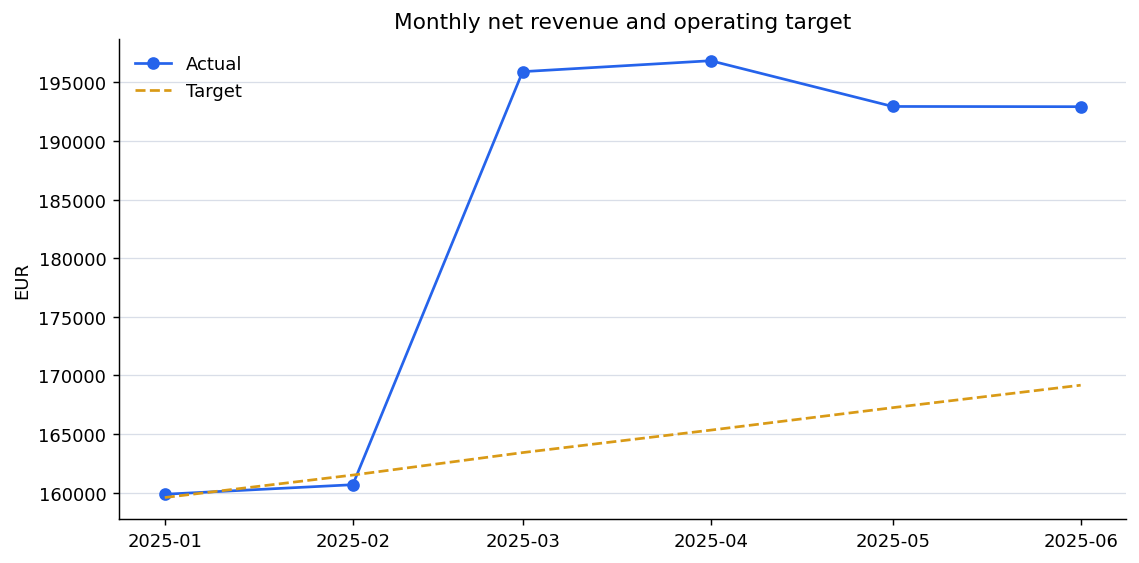

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(monthly['month_start'], monthly['net_revenue_eur'], color='#2563EB', marker='o', label='Actual')
ax.plot(monthly['month_start'], monthly['net_revenue_target_eur'], color='#D99A16', linestyle='--', label='Target')
ax.set_title('Monthly net revenue and operating target')
ax.set_ylabel('EUR')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#D9DEE8', linewidth=0.7)
ax.legend(frameon=False)
plt.show()

,stage_order,stage,sessions,stage_conversion,overall_conversion
0,1,Sessions,59976,1.000000,1.000000
1,2,Product view,59976,1.000000,1.000000
2,3,Added to cart,17742,0.295818,0.295818
3,4,Checkout started,11778,0.663848,0.196379
4,5,Purchased,8691,0.737901,0.144908


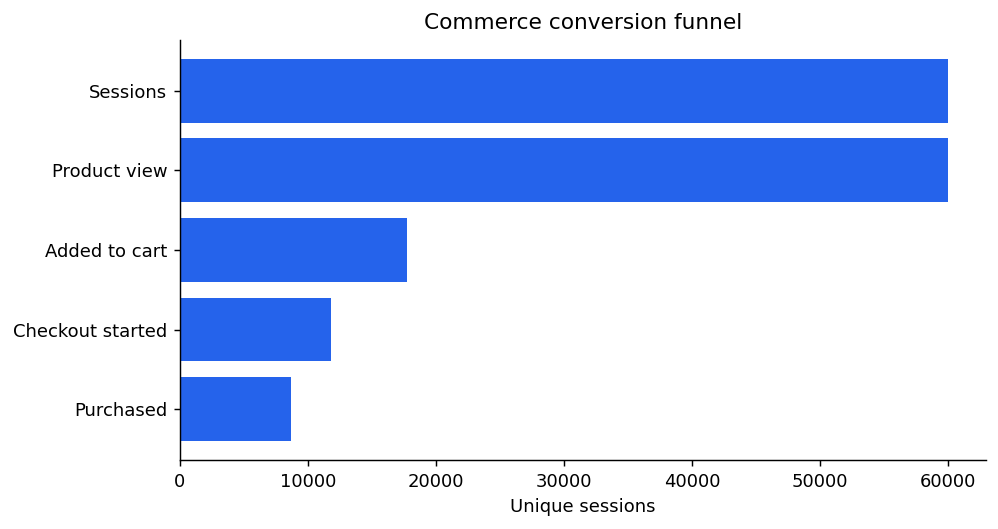

In [5]:
display(funnel[['stage_order', 'stage', 'sessions', 'stage_conversion', 'overall_conversion']])
fig, ax = plt.subplots(figsize=(8, 4.2))
view = funnel.sort_values('stage_order', ascending=False)
ax.barh(view['stage'], view['sessions'], color='#2563EB')
ax.set_title('Commerce conversion funnel')
ax.set_xlabel('Unique sessions')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

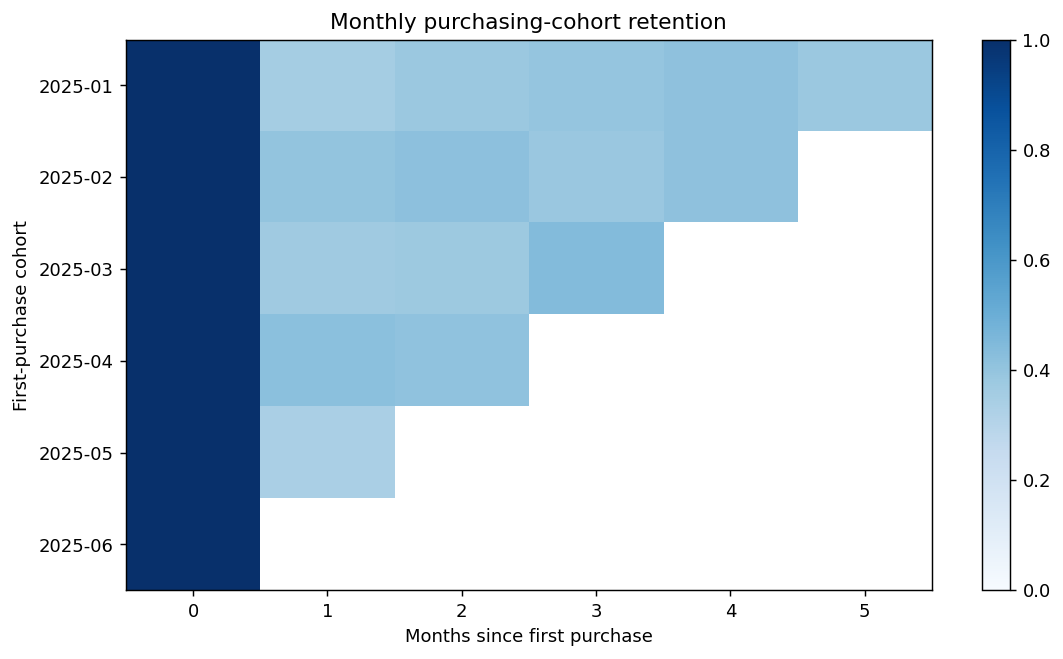

In [6]:
matrix = cohort.pivot(index='cohort_month', columns='month_index', values='retention_rate').sort_index()
fig, ax = plt.subplots(figsize=(10, 5.5))
image = ax.imshow(matrix.to_numpy(), aspect='auto', cmap='Blues', vmin=0, vmax=1)
ax.set_yticks(np.arange(len(matrix.index)), labels=matrix.index)
ax.set_xticks(np.arange(len(matrix.columns)), labels=matrix.columns)
ax.set_title('Monthly purchasing-cohort retention')
ax.set_xlabel('Months since first purchase')
ax.set_ylabel('First-purchase cohort')
fig.colorbar(image, ax=ax)
plt.show()

In [7]:
negative = roots.nsmallest(10, 'delta_contribution_margin_eur').copy()
display(negative[[
    'dimension', 'dimension_value', 'delta_net_revenue_eur',
    'delta_contribution_margin_eur', 'delta_contribution_margin_rate_pp',
    'current_return_rate'
]])

,dimension,dimension_value,delta_net_revenue_eur,delta_contribution_margin_eur,delta_contribution_margin_rate_pp,current_return_rate
14,Channel,Paid Search,22764.197839,-23144.576624,-16.833203,0.129401
18,Category,Electronics,33243.442978,-22730.646307,-11.359888,0.105125
15,Channel,Paid Social,12198.932993,-18996.962522,-28.247261,0.134066
2,Market,DE,13951.400000,-18406.260000,-11.950101,0.137334
12,Channel,Marketplace,4224.368676,-14631.365611,-30.133768,0.127753
19,Category,Home,10251.837023,-12136.117109,-11.747480,0.093685
16,Category,Apparel,2419.890497,-8840.237505,-13.563718,0.224242
20,Category,Sports,15671.376959,-6452.233812,-7.849884,0.148438
4,Market,FR,6929.320000,-5944.590000,-9.984969,0.113924
6,Market,IT,6316.980000,-5794.530000,-12.262980,0.130381


,month_start,forecast_net_revenue_eur,forecast_lower_95_eur,forecast_upper_95_eur,model
0,2025-07-01,173756.298944,151739.765370,195772.832518,OLS trend plus annual sine/cosine terms
1,2025-08-01,151707.858868,129691.325294,173724.392442,OLS trend plus annual sine/cosine terms
2,2025-09-01,129284.041742,107267.508169,151300.575316,OLS trend plus annual sine/cosine terms


Backtest diagnostics: {'backtest_method': 'Linear trend benchmark', 'holdout_months': 1, 'wape': 0.09854843447326984, 'bias': -0.09854843447326984, 'residual_std_eur': 11232.925292714333}


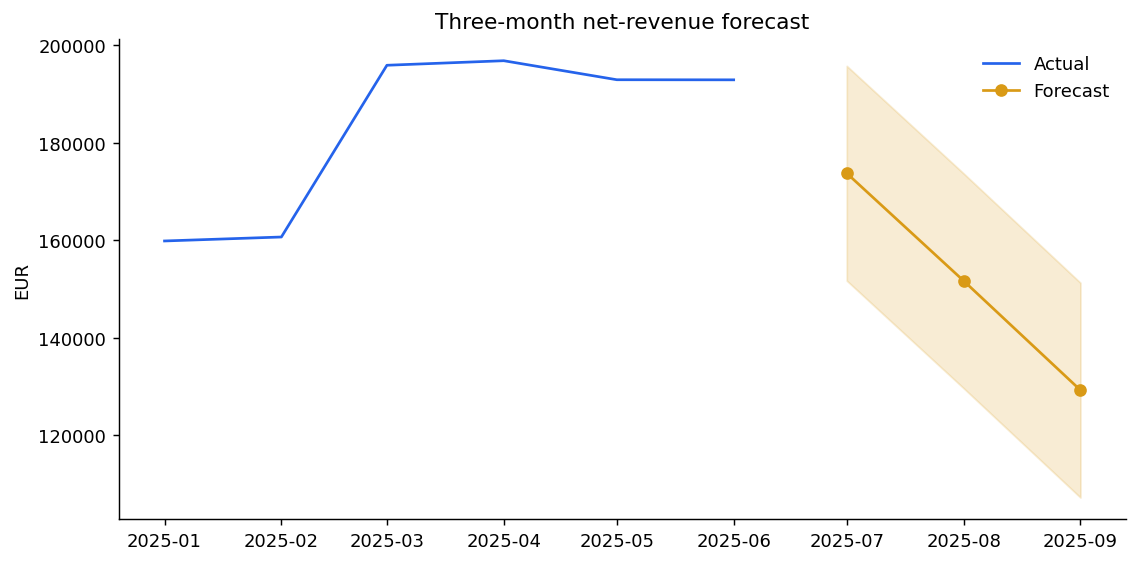

In [8]:
display(forecast)
print('Backtest diagnostics:', summary['forecast_diagnostics'])
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(monthly['month_start'], monthly['net_revenue_eur'], color='#2563EB', label='Actual')
ax.plot(forecast['month_start'], forecast['forecast_net_revenue_eur'], color='#D99A16', marker='o', label='Forecast')
ax.fill_between(
    forecast['month_start'], forecast['forecast_lower_95_eur'],
    forecast['forecast_upper_95_eur'], color='#D99A16', alpha=0.18
)
ax.set_title('Three-month net-revenue forecast')
ax.set_ylabel('EUR')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
plt.show()

## Takeaways

In [9]:
display(actions[['priority', 'owner', 'action', 'evidence', 'guardrail', 'review_cadence']])
assert actions['owner'].notna().all()
assert actions['guardrail'].notna().all()

,priority,owner,action,evidence,guardrail,review_cadence
0,P0,Commercial Director,Reprice and cap discounts for Electronics in Paid Search.,"Electronics contribution changed by EUR -22,731 in 2025Q2.",Orders and 30-day return rate must not worsen by more than 5% relative.,Weekly for six weeks
1,P0,Operations Director,Launch a delivery-SLA recovery plan for DE and the North hub.,"DE contribution changed by EUR -18,406; late delivery is an explicit return driver.",Shipping cost per fulfilled order may rise by at most EUR 0.50.,Weekly operations review
2,P1,Head of E-commerce,Prioritize mobile performance remediation in Sweden and the United Kingdom.,"Current-quarter mobile load averages 1,487 ms with 13.4% conversion in those markets.",Track conversion with Wilson confidence intervals; avoid causal claims without an experiment.,Biweekly product review
3,P1,Inventory Planning Lead,Raise reorder coverage for Electronics in DE.,"Estimated lost revenue is EUR 16,884 with a 11.1% snapshot stockout rate.",Monitor days of supply and aged stock alongside stockout rate.,Monthly S&OP


The management response should sequence four actions: (1) margin discipline in the weakest category-channel mix, (2) North-hub SLA recovery, (3) mobile performance remediation in Sweden and the United Kingdom, and (4) targeted replenishment for the largest estimated stockout opportunity. Each action has an owner, review cadence, and guardrail in the action register.

The scenario supports prioritization, not causal claims. The next real-world step would be an owned pilot or experiment with pre-registered success metrics and guardrails.